In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
import torch
import pandas as pd
import numpy as np
import os

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
print("Working directory:", os.getcwd())
print("Kaggle input folders:", os.listdir("/kaggle/input"))

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Working directory: /kaggle/working
Kaggle input folders: ['datasets']


In [7]:
import os

base = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets"

print("Path exists:", os.path.exists(base))

if os.path.exists(base):
    print("\nContents:")
    for name in os.listdir(base):
        path = os.path.join(base, name)
        if os.path.isdir(path):
            print(f"📁 {name}/")
            print("   Subfolders:", os.listdir(path)[:10])
        else:
            print(f"📄 {name}")
else:
    print("Path not found. Checking parent folder:")
    print(os.listdir("/kaggle/input/datasets/rimjhimbhura/dataset"))

Path exists: True

Contents:
📁 mvtec_anomaly_detection/
   Subfolders: ['wood', 'screw', 'metal_nut', 'capsule', 'readme.txt', 'hazelnut', 'carpet', 'pill', 'license.txt', 'grid']
📁 VisA_20220922/
   Subfolders: ['pcb2', 'pipe_fryum', 'candle', 'LICENSE-DATASET', 'fryum', 'chewinggum', 'pcb3', 'pcb1', 'split_csv', 'macaroni1']


In [8]:
import os

MVTEC = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/mvtec_anomaly_detection"

categories = ["bottle", "hazelnut", "wood", "screw"]

for category in categories:
    category_path = os.path.join(MVTEC, category)

    print(f"\n--- {category} ---")
    if not os.path.isdir(category_path):
        print("Category not found")
        continue

    for folder in ["train", "test", "ground_truth"]:
        path = os.path.join(category_path, folder)

        if os.path.isdir(path):
            print(f"{folder}: {os.listdir(path)[:6]}")
        else:
            print(f"{folder}: not found")


--- bottle ---
train: ['good']
test: ['good', 'contamination', 'broken_large', 'broken_small']
ground_truth: ['contamination', 'broken_large', 'broken_small']

--- hazelnut ---
train: ['good']
test: ['good', 'cut', 'print', 'hole', 'crack']
ground_truth: ['cut', 'print', 'hole', 'crack']

--- wood ---
train: ['good']
test: ['good', 'hole', 'liquid', 'scratch', 'color', 'combined']
ground_truth: ['hole', 'liquid', 'scratch', 'color', 'combined']

--- screw ---
train: ['good']
test: ['good', 'thread_top', 'scratch_neck', 'thread_side', 'scratch_head', 'manipulated_front']
ground_truth: ['thread_top', 'scratch_neck', 'thread_side', 'scratch_head', 'manipulated_front']


In [9]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

# Dataset paths
MVTEC = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/mvtec_anomaly_detection"
CATEGORY = "bottle"
CATEGORY_PATH = os.path.join(MVTEC, CATEGORY)

# Use GPU if available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Gather normal training images
train_dir = os.path.join(CATEGORY_PATH, "train", "good")
train_paths = [
    os.path.join(train_dir, f)
    for f in os.listdir(train_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
]

# Gather test images and their labels
test_paths, test_labels, test_masks = [], [], []

test_dir = os.path.join(CATEGORY_PATH, "test")
mask_root = os.path.join(CATEGORY_PATH, "ground_truth")

for defect_type in sorted(os.listdir(test_dir)):
    defect_dir = os.path.join(test_dir, defect_type)
    if not os.path.isdir(defect_dir):
        continue

    for filename in sorted(os.listdir(defect_dir)):
        if not filename.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
            continue

        image_path = os.path.join(defect_dir, filename)
        test_paths.append(image_path)
        test_labels.append(0 if defect_type == "good" else 1)

        if defect_type == "good":
            test_masks.append(None)
        else:
            mask_name = os.path.splitext(filename)[0] + "_mask.png"
            mask_path = os.path.join(mask_root, defect_type, mask_name)
            test_masks.append(mask_path if os.path.exists(mask_path) else None)

print("Normal training images:", len(train_paths))
print("Test images:", len(test_paths))
print("Normal test images:", test_labels.count(0))
print("Defective test images:", test_labels.count(1))
print("Missing defect masks:", sum(
    1 for label, mask in zip(test_labels, test_masks)
    if label == 1 and mask is None
))

# Load pretrained ResNet18 as a feature extractor
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
model.fc = torch.nn.Identity()
model = model.to(DEVICE).eval()

print("ResNet18 loaded successfully!")

Using device: cuda
Normal training images: 209
Test images: 83
Normal test images: 20
Defective test images: 63
Missing defect masks: 0
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 242MB/s]


ResNet18 loaded successfully!


In [10]:

import random
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

class ImagePathDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        return self.transform(image)

# Use the early ResNet18 layers to preserve spatial information.
# Output shape for a 256x256 image: [batch, 128, 32, 32]
feature_extractor = torch.nn.Sequential(
    model.conv1,
    model.bn1,
    model.relu,
    model.maxpool,
    model.layer1,
    model.layer2
).to(DEVICE).eval()

train_dataset = ImagePathDataset(train_paths, transform)
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

normal_features = []

with torch.inference_mode():
    for images in tqdm(train_loader, desc="Extracting normal features"):
        images = images.to(DEVICE)
        features = feature_extractor(images)

        # [B, C, H, W] -> [B*H*W, C]
        features = features.permute(0, 2, 3, 1).reshape(-1, 128)

        # Normalize feature vectors for distance comparison
        features = F.normalize(features, p=2, dim=1)
        normal_features.append(features.cpu())

normal_features = torch.cat(normal_features, dim=0)

print("All normal spatial features:", normal_features.shape)

# Keep a random subset as the memory bank to control memory usage.
max_memory = 10000
if len(normal_features) > max_memory:
    indices = torch.randperm(len(normal_features))[:max_memory]
    memory_bank = normal_features[indices]
else:
    memory_bank = normal_features

memory_bank = memory_bank.to(DEVICE)

print("Memory bank shape:", memory_bank.shape)
print("Feature extraction complete!")


Extracting normal features:   0%|          | 0/14 [00:00<?, ?it/s]

All normal spatial features: torch.Size([214016, 128])
Memory bank shape: torch.Size([10000, 128])
Feature extraction complete!


Scoring test images:   0%|          | 0/11 [00:00<?, ?it/s]

Scored images: 83
Image-level AUROC: 0.9992
Pixel-level AUROC (64x64 evaluation): 0.9803


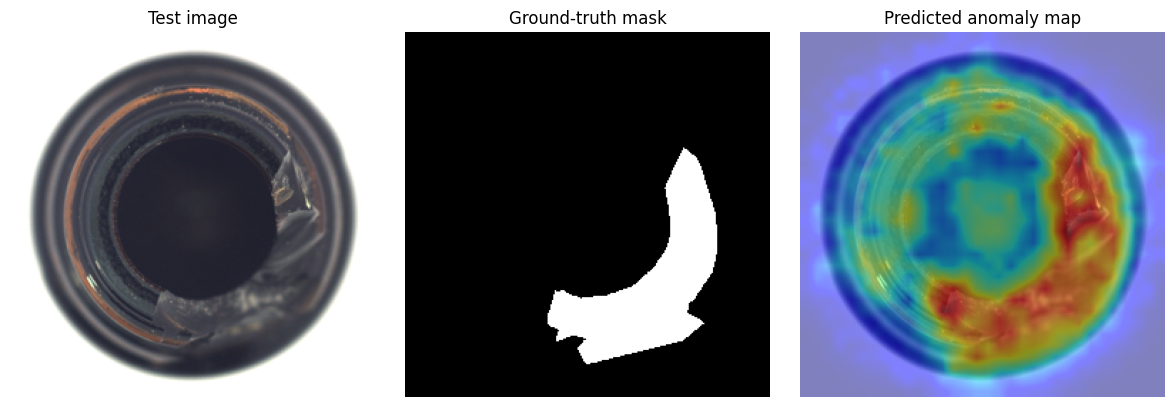

Bottle evaluation complete.


In [11]:

import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

# Keep the model and memory bank in evaluation mode
feature_extractor.eval()
memory_bank = memory_bank.to(DEVICE)

anomaly_maps = []
image_scores = []

# Reduce distance-computation memory use by processing query features in chunks
def nearest_memory_distance(query_features, bank, chunk_size=256):
    distances = []
    for chunk in query_features.split(chunk_size):
        d = torch.cdist(chunk.unsqueeze(0), bank.unsqueeze(0)).squeeze(0)
        distances.append(d.min(dim=1).values)
    return torch.cat(distances)

test_dataset = ImagePathDataset(test_paths, transform)
test_loader = DataLoader(
    test_dataset, batch_size=8, shuffle=False, num_workers=2
)

with torch.inference_mode():
    for images in tqdm(test_loader, desc="Scoring test images"):
        images = images.to(DEVICE)
        features = feature_extractor(images)

        batch_maps = []
        for feature in features:
            # [128, 32, 32] -> [1024, 128]
            patches = feature.permute(1, 2, 0).reshape(-1, 128)
            patches = F.normalize(patches, p=2, dim=1)

            # Distance to the closest normal feature
            distances = nearest_memory_distance(patches, memory_bank)
            heatmap = distances.reshape(1, 1, 32, 32)

            # Upsample anomaly map to the original evaluation size
            heatmap = F.interpolate(
                heatmap, size=(256, 256),
                mode="bilinear", align_corners=False
            ).squeeze()

            batch_maps.append(heatmap.cpu().numpy())

        for heatmap in batch_maps:
            anomaly_maps.append(heatmap)
            # Image-level score: average of the highest 1% of pixel scores
            flat = heatmap.reshape(-1)
            k = max(1, int(0.01 * len(flat)))
            image_scores.append(float(np.mean(np.partition(flat, -k)[-k:])))

print("Scored images:", len(anomaly_maps))

# Image-level AUROC
labels = np.asarray(test_labels)
scores = np.asarray(image_scores)
image_auc = roc_auc_score(labels, scores)
print(f"Image-level AUROC: {image_auc:.4f}")

# Pixel-level AUROC: use 64x64 maps/masks to limit memory usage
pixel_scores, pixel_labels = [], []
missing_masks = 0

for label, mask_path, heatmap in zip(test_labels, test_masks, anomaly_maps):
    score_small = np.asarray(
        Image.fromarray(heatmap.astype(np.float32)).resize(
            (64, 64), Image.Resampling.BILINEAR
        )
    )

    if label == 0:
        mask_small = np.zeros((64, 64), dtype=np.uint8)
    elif mask_path and os.path.exists(mask_path):
        mask = Image.open(mask_path).convert("L").resize(
            (64, 64), Image.Resampling.NEAREST
        )
        mask_small = (np.asarray(mask) > 0).astype(np.uint8)
    else:
        missing_masks += 1
        continue

    pixel_scores.extend(score_small.ravel())
    pixel_labels.extend(mask_small.ravel())

if missing_masks == 0 and len(np.unique(pixel_labels)) == 2:
    pixel_auc = roc_auc_score(pixel_labels, pixel_scores)
    print(f"Pixel-level AUROC (64x64 evaluation): {pixel_auc:.4f}")
else:
    print("Pixel AUROC skipped: missing masks or only one pixel-label class.")

# Display a defective example
defect_indices = [i for i, label in enumerate(test_labels) if label == 1]

if defect_indices:
    idx = defect_indices[0]
    original = Image.open(test_paths[idx]).convert("RGB").resize((256, 256))
    mask = Image.open(test_masks[idx]).convert("L").resize(
        (256, 256), Image.Resampling.NEAREST
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(original)
    axes[0].set_title("Test image")
    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Ground-truth mask")
    axes[2].imshow(original)
    axes[2].imshow(anomaly_maps[idx], cmap="jet", alpha=0.5)
    axes[2].set_title("Predicted anomaly map")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

print("Bottle evaluation complete.")


### Experiment 1: Unsupervised Anomaly Detection — MVTec AD Bottle

**Method:** Pretrained ResNet18 feature extractor with a nearest-neighbor memory bank.

**Training setup:** 209 normal bottle training images. No defective training images were used.

**Memory bank:** 10,000 feature vectors, each with 128 dimensions.

**Test set:** 83 images (20 normal and 63 defective).

**Results:**
- Image-level AUROC: 0.9992
- Pixel-level AUROC: 0.9803 (64×64 evaluation)

**Observation:** The baseline achieved strong image-level anomaly ranking and pixel-level discrimination on the bottle category. The predicted anomaly map highlighted the defective area, but also assigned high anomaly scores to some non-defective regions.

**Limitation:** This is a single-category experiment. Performance must be evaluated across additional categories and on VisA before drawing broader conclusions.

In [12]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

MVTEC = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/mvtec_anomaly_detection"

# Official MVTec AD category folders
categories = [
    "bottle", "cable", "capsule", "carpet", "grid",
    "hazelnut", "leather", "metal_nut", "pill", "screw",
    "tile", "toothbrush", "transistor", "wood", "zipper"
]

def list_images(folder):
    paths = []
    if os.path.isdir(folder):
        for name in sorted(os.listdir(folder)):
            path = os.path.join(folder, name)
            if os.path.isfile(path) and name.lower().endswith(
                (".png", ".jpg", ".jpeg", ".bmp")
            ):
                paths.append(path)
    return paths

def get_category_data(category):
    root = os.path.join(MVTEC, category)
    train_paths = list_images(os.path.join(root, "train", "good"))

    test_paths, labels, masks = [], [], []
    test_root = os.path.join(root, "test")
    mask_root = os.path.join(root, "ground_truth")

    for defect_type in sorted(os.listdir(test_root)):
        defect_dir = os.path.join(test_root, defect_type)
        if not os.path.isdir(defect_dir):
            continue

        for image_path in list_images(defect_dir):
            filename = os.path.basename(image_path)
            test_paths.append(image_path)
            labels.append(0 if defect_type == "good" else 1)

            if defect_type == "good":
                masks.append(None)
            else:
                mask_path = os.path.join(
                    mask_root, defect_type,
                    os.path.splitext(filename)[0] + "_mask.png"
                )
                masks.append(mask_path if os.path.exists(mask_path) else None)

    return train_paths, test_paths, labels, masks

def extract_spatial_features(paths, batch_size=16):
    dataset = ImagePathDataset(paths, transform)
    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=False,
        num_workers=2, pin_memory=True
    )

    output = []
    with torch.inference_mode():
        for images in loader:
            images = images.to(DEVICE)
            feat = feature_extractor(images)
            # [B,C,H,W] -> [B*H*W,C]
            feat = feat.permute(0, 2, 3, 1).reshape(-1, 128)
            feat = F.normalize(feat, p=2, dim=1)
            output.append(feat.cpu())

    return torch.cat(output, dim=0)

def score_image(path, bank):
    dataset = ImagePathDataset([path], transform)
    image = dataset[0].unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        feat = feature_extractor(image)[0]
        patches = feat.permute(1, 2, 0).reshape(-1, 128)
        patches = F.normalize(patches, p=2, dim=1)

        # Chunk queries to limit GPU memory
        distances = []
        for chunk in patches.split(128):
            d = torch.cdist(
                chunk.unsqueeze(0), bank.unsqueeze(0)
            ).squeeze(0)
            distances.append(d.min(dim=1).values)

        dist = torch.cat(distances).reshape(1, 1, 32, 32)
        heatmap = F.interpolate(
            dist, size=(256, 256),
            mode="bilinear", align_corners=False
        )[0, 0].cpu().numpy()

    flat = heatmap.ravel()
    k = max(1, int(0.01 * len(flat)))
    return heatmap, float(np.mean(np.partition(flat, -k)[-k:]))

results = []

for category in categories:
    print(f"\nEvaluating {category}...")
    train_paths, test_paths, labels, masks = get_category_data(category)

    if not train_paths or not test_paths:
        print("Skipping: missing train or test images.")
        continue

    # Extract normal features for this category only
    train_features = extract_spatial_features(train_paths)

    # Randomly sample up to 10,000 reference patches
    if len(train_features) > 10000:
        generator = torch.Generator().manual_seed(42)
        indices = torch.randperm(
            len(train_features), generator=generator
        )[:10000]
        train_features = train_features[indices]

    bank = train_features.to(DEVICE)
    scores, heatmaps = [], []

    for path in tqdm(test_paths, leave=False):
        heatmap, score = score_image(path, bank)
        heatmaps.append(heatmap)
        scores.append(score)

    labels_arr = np.asarray(labels)
    image_auc = (
        roc_auc_score(labels_arr, scores)
        if len(np.unique(labels_arr)) == 2 else np.nan
    )

    # Pixel AUROC using 64x64 heatmaps and masks
    pixel_scores, pixel_labels = [], []
    missing_masks = 0

    for label, mask_path, heatmap in zip(labels, masks, heatmaps):
        score_small = np.asarray(
            Image.fromarray(heatmap.astype(np.float32)).resize(
                (64, 64), Image.Resampling.BILINEAR
            )
        )

        if label == 0:
            mask_small = np.zeros((64, 64), dtype=np.uint8)
        elif mask_path and os.path.exists(mask_path):
            mask_img = Image.open(mask_path).convert("L").resize(
                (64, 64), Image.Resampling.NEAREST
            )
            mask_small = (
                np.asarray(mask_img) > 0
            ).astype(np.uint8)
        else:
            missing_masks += 1
            continue

        pixel_scores.extend(score_small.ravel())
        pixel_labels.extend(mask_small.ravel())

    if (
        missing_masks == 0
        and len(np.unique(pixel_labels)) == 2
    ):
        pixel_auc = roc_auc_score(pixel_labels, pixel_scores)
    else:
        pixel_auc = np.nan

    results.append({
        "category": category,
        "train_images": len(train_paths),
        "test_images": len(test_paths),
        "image_AUROC": image_auc,
        "pixel_AUROC_64": pixel_auc,
        "missing_masks": missing_masks
    })

    print(
        f"Image AUROC: {image_auc:.4f} | "
        f"Pixel AUROC: {pixel_auc:.4f}"
    )

results_df = pd.DataFrame(results)

print("\nPer-category results:")
display(results_df.round(4))

print("\nMean category AUROC:")
print("Image AUROC:", round(results_df["image_AUROC"].mean(), 4))
print("Pixel AUROC:", round(results_df["pixel_AUROC_64"].mean(), 4))

os.makedirs("/kaggle/working/results", exist_ok=True)
results_df.to_csv(
    "/kaggle/working/results/mvtec_unsupervised_results.csv",
    index=False
)
print("\nSaved results to /kaggle/working/results/mvtec_unsupervised_results.csv")



Evaluating bottle...


  0%|          | 0/83 [00:00<?, ?it/s]

Image AUROC: 0.9992 | Pixel AUROC: 0.9804

Evaluating cable...


  0%|          | 0/150 [00:00<?, ?it/s]

Image AUROC: 0.9582 | Pixel AUROC: 0.8914

Evaluating capsule...


...

Image AUROC: 0.9904 | Pixel AUROC: 0.9413

Evaluating zipper...


  0%|          | 0/151 [00:00<?, ?it/s]

Image AUROC: 0.9701 | Pixel AUROC: 0.9477

Per-category results:


,category,train_images,test_images,image_AUROC,pixel_AUROC_64,missing_masks
0,bottle,209,83,0.9992,0.9804,0
1,cable,224,150,0.9582,0.8914,0
2,capsule,219,132,0.8708,0.9639,0
3,carpet,280,117,0.9996,0.9809,0
4,grid,264,78,0.9449,0.9793,0
5,hazelnut,391,110,0.9875,0.9734,0
6,leather,245,124,1.0000,0.9960,0
7,metal_nut,220,115,0.9677,0.9064,0
8,pill,267,167,0.9531,0.9264,0
9,screw,320,160,0.6891,0.9730,0



Mean category AUROC:
Image AUROC: 0.9479
Pixel AUROC: 0.9395

Saved results to /kaggle/working/results/mvtec_unsupervised_results.csv


### Experiment: Unsupervised Anomaly Detection on MVTec AD

**Method:** ImageNet-pretrained ResNet18 feature extractor with a nearest-neighbor memory bank containing normal training features.

**Training protocol:** The model's memory bank was constructed from normal training images for each category. The official test sets were used for evaluation.

**Dataset coverage:** All 15 MVTec AD categories.

**Results:**
- Mean image-level AUROC: 0.9479
- Mean pixel-level AUROC: 0.9395, evaluated using 64×64 anomaly maps and ground-truth masks.

**Best image-level results:** Leather (1.0000), carpet (0.9996), and bottle (0.9992).

**Main challenges:** Screw (0.6891 image AUROC), capsule (0.8708), and transistor (0.9171). Transistor also had the lowest pixel-level AUROC (0.7416).

**Conclusion:** The baseline showed promising anomaly detection and localization performance across MVTec AD, with substantial category-dependent variation. Further experiments on VisA and cross-dataset evaluation are required before drawing conclusions about generalization.

In [13]:

import os

VISA = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/VisA_20220922"

print("VisA folder exists:", os.path.exists(VISA))
print("\nTop-level contents:")

for name in sorted(os.listdir(VISA)):
    path = os.path.join(VISA, name)

    if os.path.isdir(path):
        print(f"\n📁 {name}/")
        print("   Contents:", sorted(os.listdir(path))[:12])
    else:
        print(f"📄 {name}")


VisA folder exists: True

Top-level contents:
📄 LICENSE-DATASET

📁 candle/
   Contents: ['Data', 'image_anno.csv']

📁 capsules/
   Contents: ['Data', 'image_anno.csv']

📁 cashew/
   Contents: ['Data', 'image_anno.csv']

📁 chewinggum/
   Contents: ['Data', 'image_anno.csv']

📁 fryum/
   Contents: ['Data', 'image_anno.csv']

📁 macaroni1/
   Contents: ['Data', 'image_anno.csv']

📁 macaroni2/
   Contents: ['Data', 'image_anno.csv']

📁 pcb1/
   Contents: ['Data', 'image_anno.csv']

📁 pcb2/
   Contents: ['Data', 'image_anno.csv']

📁 pcb3/
   Contents: ['Data', 'image_anno.csv']

📁 pcb4/
   Contents: ['Data', 'image_anno.csv']

📁 pipe_fryum/
   Contents: ['Data', 'image_anno.csv']

📁 split_csv/
   Contents: ['1cls.csv', '2cls_fewshot.csv', '2cls_highshot.csv']


In [14]:

import os
import pandas as pd

VISA = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/VisA_20220922"

# Inspect one category's annotation file
csv_path = os.path.join(VISA, "candle", "image_anno.csv")
annotations = pd.read_csv(csv_path)

print("Annotation columns:")
print(annotations.columns.tolist())

print("\nFirst five rows:")
display(annotations.head())

print("\nAnnotation file shape:", annotations.shape)

# Inspect official one-class split file
split_path = os.path.join(VISA, "split_csv", "1cls.csv")
splits = pd.read_csv(split_path)

print("\nOfficial split columns:")
print(splits.columns.tolist())

print("\nFirst five split rows:")
display(splits.head())

print("\nSplit file shape:", splits.shape)


Annotation columns:
['image', 'label', 'mask']

First five rows:


,image,label,mask
0,candle/Data/Images/Normal/0000.JPG,normal,NaN
1,candle/Data/Images/Normal/0001.JPG,normal,NaN
2,candle/Data/Images/Normal/0002.JPG,normal,NaN
3,candle/Data/Images/Normal/0003.JPG,normal,NaN
4,candle/Data/Images/Normal/0004.JPG,normal,NaN



Annotation file shape: (1100, 3)

Official split columns:
['object', 'split', 'label', 'image', 'mask']

First five split rows:


,object,split,label,image,mask
0,candle,train,normal,candle/Data/Images/Normal/0836.JPG,NaN
1,candle,train,normal,candle/Data/Images/Normal/0451.JPG,NaN
2,candle,train,normal,candle/Data/Images/Normal/0516.JPG,NaN
3,candle,train,normal,candle/Data/Images/Normal/0977.JPG,NaN
4,candle,train,normal,candle/Data/Images/Normal/0249.JPG,NaN



Split file shape: (10821, 5)


In [15]:

import os
import pandas as pd

VISA = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/VisA_20220922"
split_csv = os.path.join(VISA, "split_csv", "1cls.csv")

visa_splits = pd.read_csv(split_csv)

# Keep the candle category
candle = visa_splits[visa_splits["object"] == "candle"].copy()

print("Candle split counts:")
print(pd.crosstab(candle["split"], candle["label"], margins=True))

print("\nExample training rows:")
display(candle[candle["split"] == "train"].head())

print("\nExample test rows:")
display(candle[candle["split"] == "test"].head())

# Check whether image paths resolve correctly
for _, row in candle.head(10).iterrows():
    image_path = os.path.join(VISA, row["image"])
    print("Exists:", os.path.exists(image_path), "|", row["image"])


Candle split counts:
label  anomaly  normal   All
split                       
test       100     100   200
train        0     900   900
All        100    1000  1100

Example training rows:


,object,split,label,image,mask
0,candle,train,normal,candle/Data/Images/Normal/0836.JPG,NaN
1,candle,train,normal,candle/Data/Images/Normal/0451.JPG,NaN
2,candle,train,normal,candle/Data/Images/Normal/0516.JPG,NaN
3,candle,train,normal,candle/Data/Images/Normal/0977.JPG,NaN
4,candle,train,normal,candle/Data/Images/Normal/0249.JPG,NaN



Example test rows:


,object,split,label,image,mask
900,candle,test,normal,candle/Data/Images/Normal/0790.JPG,NaN
901,candle,test,normal,candle/Data/Images/Normal/0107.JPG,NaN
902,candle,test,normal,candle/Data/Images/Normal/0484.JPG,NaN
903,candle,test,normal,candle/Data/Images/Normal/0690.JPG,NaN
904,candle,test,normal,candle/Data/Images/Normal/0303.JPG,NaN


Exists: True | candle/Data/Images/Normal/0836.JPG
Exists: True | candle/Data/Images/Normal/0451.JPG
Exists: True | candle/Data/Images/Normal/0516.JPG
Exists: True | candle/Data/Images/Normal/0977.JPG
Exists: True | candle/Data/Images/Normal/0249.JPG
Exists: True | candle/Data/Images/Normal/0548.JPG
Exists: True | candle/Data/Images/Normal/0362.JPG
Exists: True | candle/Data/Images/Normal/0074.JPG
Exists: True | candle/Data/Images/Normal/0650.JPG
Exists: True | candle/Data/Images/Normal/0898.JPG


In [16]:

# Inspect anomalous test rows and their mask paths
anomalies = candle[
    (candle["split"] == "test") &
    (candle["label"] == "anomaly")
]

print("Number of anomalous test images:", len(anomalies))
print("\nFirst 5 anomaly records:")

for _, row in anomalies.head(5).iterrows():
    image_path = os.path.join(VISA, row["image"])

    mask_value = row["mask"]
    mask_path = (
        os.path.join(VISA, str(mask_value))
        if pd.notna(mask_value) and str(mask_value).strip()
        else None
    )

    print("\nImage:", row["image"])
    print("Image exists:", os.path.exists(image_path))
    print("Mask:", mask_value)
    print("Mask exists:", mask_path is not None and os.path.exists(mask_path))


Number of anomalous test images: 100

First 5 anomaly records:

Image: candle/Data/Images/Anomaly/000.JPG
Image exists: True
Mask: candle/Data/Masks/Anomaly/000.png
Mask exists: True

Image: candle/Data/Images/Anomaly/001.JPG
Image exists: True
Mask: candle/Data/Masks/Anomaly/001.png
Mask exists: True

Image: candle/Data/Images/Anomaly/002.JPG
Image exists: True
Mask: candle/Data/Masks/Anomaly/002.png
Mask exists: True

Image: candle/Data/Images/Anomaly/003.JPG
Image exists: True
Mask: candle/Data/Masks/Anomaly/003.png
Mask exists: True

Image: candle/Data/Images/Anomaly/004.JPG
Image exists: True
Mask: candle/Data/Masks/Anomaly/004.png
Mask exists: True


Normal training images: 900
Test images: 200
Normal test images: 100
Anomalous test images: 100
Missing anomaly masks: 0


Extracting VisA normal features:   0%|          | 0/57 [00:00<?, ?it/s]

VisA memory bank: (10000, 128)


Scoring VisA test images:   0%|          | 0/25 [00:00<?, ?it/s]


VisA candle image-level AUROC: 0.9240
VisA candle pixel-level AUROC (64x64): 0.9462


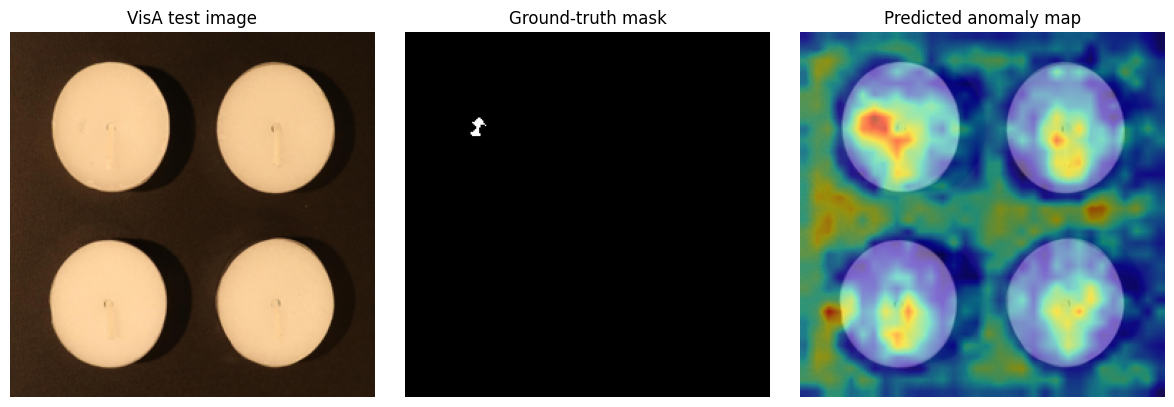


Saved: /kaggle/working/results/visa_candle_results.csv


In [17]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

VISA = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/VisA_20220922"
category = "candle"

# Load official one-class split
visa_splits = pd.read_csv(os.path.join(VISA, "split_csv", "1cls.csv"))
data = visa_splits[
    (visa_splits["object"] == category) &
    (visa_splits["split"].isin(["train", "test"]))
].copy()

train_df = data[
    (data["split"] == "train") &
    (data["label"] == "normal")
].reset_index(drop=True)

test_df = data[data["split"] == "test"].reset_index(drop=True)

train_paths = [os.path.join(VISA, p) for p in train_df["image"]]
test_paths = [os.path.join(VISA, p) for p in test_df["image"]]
test_labels = (test_df["label"] == "anomaly").astype(int).tolist()
test_masks = [
    os.path.join(VISA, str(p))
    if pd.notna(p) and str(p).strip() else None
    for p in test_df["mask"]
]

print("Normal training images:", len(train_paths))
print("Test images:", len(test_paths))
print("Normal test images:", test_labels.count(0))
print("Anomalous test images:", test_labels.count(1))
print("Missing anomaly masks:", sum(
    1 for label, mask in zip(test_labels, test_masks)
    if label == 1 and (mask is None or not os.path.exists(mask))
))

# Extract normal training features
train_dataset = ImagePathDataset(train_paths, transform)
train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=False,
    num_workers=2, pin_memory=True
)

feature_list = []
feature_extractor.eval()

with torch.inference_mode():
    for images in tqdm(train_loader, desc="Extracting VisA normal features"):
        images = images.to(DEVICE)
        features = feature_extractor(images)
        features = features.permute(0, 2, 3, 1).reshape(-1, 128)
        features = F.normalize(features, p=2, dim=1)
        feature_list.append(features.cpu())

normal_features_visa = torch.cat(feature_list, dim=0)

# Random memory-bank sampling
max_memory = 10000
if len(normal_features_visa) > max_memory:
    generator = torch.Generator().manual_seed(42)
    indices = torch.randperm(
        len(normal_features_visa), generator=generator
    )[:max_memory]
    normal_features_visa = normal_features_visa[indices]

memory_bank_visa = normal_features_visa.to(DEVICE)
print("VisA memory bank:", tuple(memory_bank_visa.shape))

# Score each test image
anomaly_maps_visa = []
image_scores_visa = []

test_dataset = ImagePathDataset(test_paths, transform)
test_loader = DataLoader(
    test_dataset, batch_size=8, shuffle=False, num_workers=2
)

with torch.inference_mode():
    for images in tqdm(test_loader, desc="Scoring VisA test images"):
        images = images.to(DEVICE)
        batch_features = feature_extractor(images)

        for features in batch_features:
            patches = features.permute(1, 2, 0).reshape(-1, 128)
            patches = F.normalize(patches, p=2, dim=1)

            distance_parts = []
            for chunk in patches.split(128):
                d = torch.cdist(
                    chunk.unsqueeze(0),
                    memory_bank_visa.unsqueeze(0)
                ).squeeze(0)
                distance_parts.append(d.min(dim=1).values)

            distances = torch.cat(distance_parts).reshape(1, 1, 32, 32)
            heatmap = F.interpolate(
                distances, size=(256, 256),
                mode="bilinear", align_corners=False
            )[0, 0].cpu().numpy()

            anomaly_maps_visa.append(heatmap)
            flat = heatmap.ravel()
            k = max(1, int(0.01 * len(flat)))
            image_scores_visa.append(
                float(np.mean(np.partition(flat, -k)[-k:]))
            )

# Image-level AUROC
labels_array = np.asarray(test_labels)
scores_array = np.asarray(image_scores_visa)
image_auc_visa = roc_auc_score(labels_array, scores_array)

print(f"\nVisA candle image-level AUROC: {image_auc_visa:.4f}")

# Pixel-level AUROC at 64x64
pixel_scores, pixel_labels = [], []
missing_masks = 0

for label, mask_path, heatmap in zip(
    test_labels, test_masks, anomaly_maps_visa
):
    score_small = np.asarray(
        Image.fromarray(heatmap.astype(np.float32)).resize(
            (64, 64), Image.Resampling.BILINEAR
        )
    )

    if label == 0:
        mask_small = np.zeros((64, 64), dtype=np.uint8)
    elif mask_path and os.path.exists(mask_path):
        mask_img = Image.open(mask_path).convert("L").resize(
            (64, 64), Image.Resampling.NEAREST
        )
        mask_small = (np.asarray(mask_img) > 0).astype(np.uint8)
    else:
        missing_masks += 1
        continue

    pixel_scores.extend(score_small.ravel())
    pixel_labels.extend(mask_small.ravel())

if missing_masks == 0 and len(np.unique(pixel_labels)) == 2:
    pixel_auc_visa = roc_auc_score(pixel_labels, pixel_scores)
    print(f"VisA candle pixel-level AUROC (64x64): {pixel_auc_visa:.4f}")
else:
    pixel_auc_visa = np.nan
    print("Pixel AUROC unavailable: missing masks or only one pixel class.")

# Visualize the first anomalous test image
anomaly_indices = [i for i, label in enumerate(test_labels) if label == 1]

if anomaly_indices:
    idx = anomaly_indices[0]
    original = Image.open(test_paths[idx]).convert("RGB").resize((256, 256))
    mask = Image.open(test_masks[idx]).convert("L").resize(
        (256, 256), Image.Resampling.NEAREST
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(original)
    axes[0].set_title("VisA test image")
    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Ground-truth mask")
    axes[2].imshow(original)
    axes[2].imshow(anomaly_maps_visa[idx], cmap="jet", alpha=0.5)
    axes[2].set_title("Predicted anomaly map")

    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Save experiment result
os.makedirs("/kaggle/working/results", exist_ok=True)
visa_result = pd.DataFrame([{
    "dataset": "VisA",
    "category": category,
    "train_images": len(train_paths),
    "test_images": len(test_paths),
    "image_AUROC": image_auc_visa,
    "pixel_AUROC_64": pixel_auc_visa,
    "missing_masks": missing_masks
}])

visa_result.to_csv(
    "/kaggle/working/results/visa_candle_results.csv",
    index=False
)

print("\nSaved: /kaggle/working/results/visa_candle_results.csv")


In [18]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

VISA = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/VisA_20220922"
RESULT_DIR = "/kaggle/working/results"
os.makedirs(RESULT_DIR, exist_ok=True)

visa_splits = pd.read_csv(os.path.join(VISA, "split_csv", "1cls.csv"))
categories = sorted(visa_splits["object"].unique())

print("Number of VisA categories:", len(categories))
print("Categories:", categories)

def get_normal_features(paths, max_memory=10000):
    dataset = ImagePathDataset(paths, transform)
    loader = DataLoader(
        dataset, batch_size=16, shuffle=False,
        num_workers=2, pin_memory=True
    )
    features_list = []

    with torch.inference_mode():
        for images in loader:
            images = images.to(DEVICE)
            features = feature_extractor(images)
            features = features.permute(0, 2, 3, 1).reshape(-1, 128)
            features = F.normalize(features, p=2, dim=1)
            features_list.append(features.cpu())

    features_all = torch.cat(features_list, dim=0)

    if len(features_all) > max_memory:
        generator = torch.Generator().manual_seed(42)
        indices = torch.randperm(
            len(features_all), generator=generator
        )[:max_memory]
        features_all = features_all[indices]

    return features_all.to(DEVICE)

def evaluate_category(category):
    data = visa_splits[
        (visa_splits["object"] == category) &
        (visa_splits["split"].isin(["train", "test"]))
    ].copy()

    train_df = data[
        (data["split"] == "train") &
        (data["label"] == "normal")
    ].reset_index(drop=True)

    test_df = data[data["split"] == "test"].reset_index(drop=True)

    train_paths = [os.path.join(VISA, p) for p in train_df["image"]]
    test_paths = [os.path.join(VISA, p) for p in test_df["image"]]
    labels = (test_df["label"] == "anomaly").astype(int).to_numpy()

    if len(train_paths) == 0 or len(np.unique(labels)) < 2:
        raise ValueError("Missing normal training images or test classes.")

    # Memory bank contains only normal training features
    memory_bank = get_normal_features(train_paths)
    maps = []
    image_scores = []

    dataset = ImagePathDataset(test_paths, transform)
    loader = DataLoader(
        dataset, batch_size=8, shuffle=False, num_workers=2
    )

    with torch.inference_mode():
        for images in loader:
            images = images.to(DEVICE)
            batch_features = feature_extractor(images)

            for features in batch_features:
                patches = features.permute(1, 2, 0).reshape(-1, 128)
                patches = F.normalize(patches, p=2, dim=1)

                distances = []
                for chunk in patches.split(128):
                    d = torch.cdist(
                        chunk.unsqueeze(0),
                        memory_bank.unsqueeze(0)
                    ).squeeze(0)
                    distances.append(d.min(dim=1).values)

                heatmap = torch.cat(distances).reshape(1, 1, 32, 32)
                heatmap = F.interpolate(
                    heatmap, size=(256, 256),
                    mode="bilinear", align_corners=False
                )[0, 0].cpu().numpy()

                maps.append(heatmap)
                flat = heatmap.ravel()
                k = max(1, int(0.01 * len(flat)))
                image_scores.append(
                    float(np.mean(np.partition(flat, -k)[-k:]))
                )

    image_auc = roc_auc_score(labels, image_scores)

    pixel_scores = []
    pixel_labels = []
    missing_masks = 0

    for label, mask_value, heatmap in zip(
        labels, test_df["mask"].tolist(), maps
    ):
        score_small = np.asarray(
            Image.fromarray(heatmap.astype(np.float32)).resize(
                (64, 64), Image.Resampling.BILINEAR
            )
        )

        if label == 0:
            mask_small = np.zeros((64, 64), dtype=np.uint8)
        else:
            mask_path = (
                os.path.join(VISA, str(mask_value))
                if pd.notna(mask_value) and str(mask_value).strip()
                else None
            )

            if mask_path is None or not os.path.exists(mask_path):
                missing_masks += 1
                continue

            mask_img = Image.open(mask_path).convert("L").resize(
                (64, 64), Image.Resampling.NEAREST
            )
            mask_small = (
                np.asarray(mask_img) > 0
            ).astype(np.uint8)

        pixel_scores.extend(score_small.ravel())
        pixel_labels.extend(mask_small.ravel())

    if missing_masks == 0 and len(np.unique(pixel_labels)) == 2:
        pixel_auc = roc_auc_score(pixel_labels, pixel_scores)
    else:
        pixel_auc = np.nan

    return {
        "dataset": "VisA",
        "category": category,
        "train_images": len(train_paths),
        "test_images": len(test_paths),
        "image_AUROC": image_auc,
        "pixel_AUROC_64": pixel_auc,
        "missing_masks": missing_masks
    }

# Evaluate all categories and save progress after every category
results = []

for category in categories:
    print(f"\nEvaluating {category}...")
    try:
        result = evaluate_category(category)
        results.append(result)

        pd.DataFrame(results).to_csv(
            os.path.join(RESULT_DIR, "visa_unsupervised_results.csv"),
            index=False
        )

        print(
            f"Image AUROC: {result['image_AUROC']:.4f} | "
            f"Pixel AUROC: {result['pixel_AUROC_64']:.4f} | "
            f"Missing masks: {result['missing_masks']}"
        )
    except Exception as error:
        print(f"ERROR for {category}: {error}")

print("\n--- VisA results so far ---")
visa_results = pd.DataFrame(results)
display(visa_results)

if len(visa_results):
    print("\nMean category image AUROC:",
          round(visa_results["image_AUROC"].mean(), 4))
    print("Mean category pixel AUROC:",
          round(visa_results["pixel_AUROC_64"].mean(), 4))

print("\nSaved results to:",
      os.path.join(RESULT_DIR, "visa_unsupervised_results.csv"))


Number of VisA categories: 12
Categories: ['candle', 'capsules', 'cashew', 'chewinggum', 'fryum', 'macaroni1', 'macaroni2', 'pcb1', 'pcb2', 'pcb3', 'pcb4', 'pipe_fryum']

Evaluating candle...
Image AUROC: 0.9240 | Pixel AUROC: 0.9462 | Missing masks: 0

Evaluating capsules...
Image AUROC: 0.7322 | Pixel AUROC: 0.9072 | Missing masks: 0

Evaluating cashew...
Image AUROC: 0.9600 | Pixel AUROC: 0.7051 | Missing masks: 0

Evaluating chewinggum...
Image AUROC: 0.9508 | Pixel AUROC: 0.9564 | Missing masks: 0

Evaluating fryum...
Image AUROC: 0.8868 | Pixel AUROC: 0.9137 | Missing masks: 0

Evaluating macaroni1...
Image AUROC: 0.8224 | Pixel AUROC: 0.9578 | Missing masks: 0

Evaluating macaroni2...
Image AUROC: 0.6335 | Pixel AUROC: 0.9553 | Missing masks: 0

Evaluating pcb1...
Image AUROC: 0.9472 | Pixel AUROC: 0.9394 | Missing masks: 0

Evaluating pcb2...
Image AUROC: 0.8689 | Pixel AUROC: 0.9398 | Missing masks: 0

Evaluating pcb3...
Image AUROC: 0.8825 | Pixel AUROC: 0.9763 | Missing mask

,dataset,category,train_images,test_images,image_AUROC,pixel_AUROC_64,missing_masks
0,VisA,candle,900,200,0.924000,0.946150,0
1,VisA,capsules,542,160,0.732167,0.907203,0
2,VisA,cashew,450,150,0.960000,0.705123,0
3,VisA,chewinggum,453,150,0.950800,0.956444,0
4,VisA,fryum,450,150,0.886800,0.913658,0
5,VisA,macaroni1,900,200,0.822400,0.957775,0
6,VisA,macaroni2,900,200,0.633500,0.955338,0
7,VisA,pcb1,904,200,0.947200,0.939449,0
8,VisA,pcb2,901,200,0.868900,0.939830,0
9,VisA,pcb3,905,201,0.882475,0.976265,0



Mean category image AUROC: 0.8824
Mean category pixel AUROC: 0.9262

Saved results to: /kaggle/working/results/visa_unsupervised_results.csv


In [19]:

import os
import pandas as pd

MVTEC = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/mvtec_anomaly_detection"
VISA = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/VisA_20220922"

# Inspect available MVTec categories
mvtec_categories = sorted([
    name for name in os.listdir(MVTEC)
    if os.path.isdir(os.path.join(MVTEC, name))
])

# Inspect VisA categories from the official one-class split
visa_splits = pd.read_csv(os.path.join(VISA, "split_csv", "1cls.csv"))
visa_categories = sorted(visa_splits["object"].unique())

print("MVTec categories:")
print(mvtec_categories)

print("\nVisA categories:")
print(visa_categories)

# Check the category folders we will use for the first transfer test
source_category = "bottle"
target_category = "candle"

print("\nSource category exists:",
      os.path.isdir(os.path.join(MVTEC, source_category)))
print("Target category exists:",
      target_category in visa_categories)


MVTec categories:
['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']

VisA categories:
['candle', 'capsules', 'cashew', 'chewinggum', 'fryum', 'macaroni1', 'macaroni2', 'pcb1', 'pcb2', 'pcb3', 'pcb4', 'pipe_fryum']

Source category exists: True
Target category exists: True


In [20]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

MVTEC = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/mvtec_anomaly_detection"
source_category = "bottle"

# MVTec bottle training images are stored under train/good
source_train_dir = os.path.join(
    MVTEC, source_category, "train", "good"
)

source_train_paths = sorted([
    os.path.join(source_train_dir, name)
    for name in os.listdir(source_train_dir)
    if name.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
])

print("Normal MVTec bottle training images:", len(source_train_paths))
print("First image:", source_train_paths[0] if source_train_paths else "None")

assert len(source_train_paths) > 0, "No source training images found."

# Extract spatial features from normal MVTec bottle images
source_dataset = ImagePathDataset(source_train_paths, transform)
source_loader = DataLoader(
    source_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

source_feature_list = []
feature_extractor.eval()

with torch.inference_mode():
    for images in tqdm(source_loader, desc="Building MVTec source bank"):
        images = images.to(DEVICE)
        features = feature_extractor(images)
        features = features.permute(0, 2, 3, 1).reshape(-1, 128)
        features = F.normalize(features, p=2, dim=1)
        source_feature_list.append(features.cpu())

source_features = torch.cat(source_feature_list, dim=0)

# Keep the bank capped at 10,000 patch features
max_memory = 10000
if len(source_features) > max_memory:
    generator = torch.Generator().manual_seed(42)
    indices = torch.randperm(
        len(source_features), generator=generator
    )[:max_memory]
    source_features = source_features[indices]

mvtec_bottle_memory_bank = source_features.to(DEVICE)

print("\nSource memory bank ready.")
print("Memory bank shape:", tuple(mvtec_bottle_memory_bank.shape))
print("Feature device:", mvtec_bottle_memory_bank.device)


Normal MVTec bottle training images: 209
First image: /kaggle/input/datasets/rimjhimbhura/dataset/datasets/mvtec_anomaly_detection/bottle/train/good/000.png


Building MVTec source bank:   0%|          | 0/14 [00:00<?, ?it/s]


Source memory bank ready.
Memory bank shape: (10000, 128)
Feature device: cuda:0


Target dataset: VisA
Target category: candle
Test images: 200
Normal images: 100
Anomalous images: 100


Cross-dataset evaluation:   0%|          | 0/25 [00:00<?, ?it/s]


MVTec bottle -> VisA candle image AUROC: 0.6329
MVTec bottle -> VisA candle pixel AUROC (64x64): 0.8839
Missing masks: 0


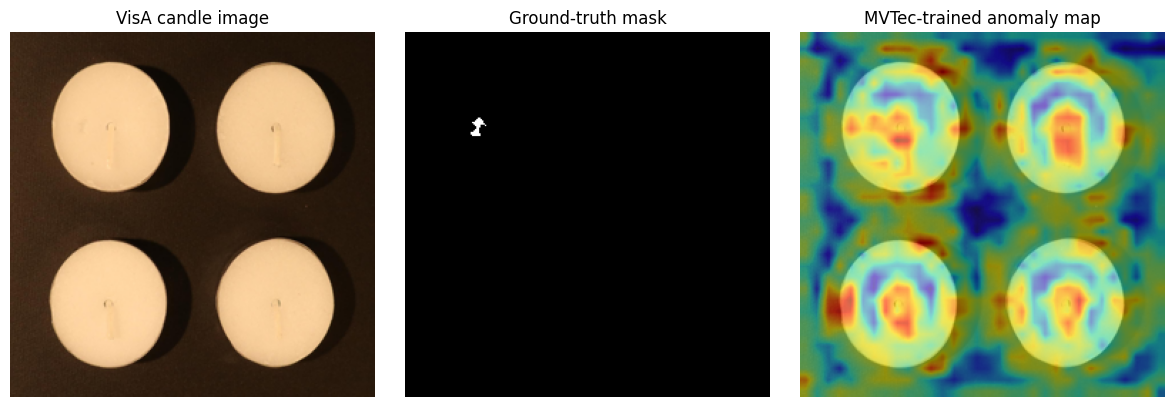


Saved cross-dataset result.


In [21]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

VISA = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/VisA_20220922"
target_category = "candle"

visa_splits = pd.read_csv(os.path.join(VISA, "split_csv", "1cls.csv"))

target_df = visa_splits[
    (visa_splits["object"] == target_category) &
    (visa_splits["split"] == "test")
].reset_index(drop=True)

target_paths = [
    os.path.join(VISA, path) for path in target_df["image"]
]
target_labels = (
    target_df["label"] == "anomaly"
).astype(int).to_numpy()

print("Target dataset: VisA")
print("Target category:", target_category)
print("Test images:", len(target_paths))
print("Normal images:", int((target_labels == 0).sum()))
print("Anomalous images:", int((target_labels == 1).sum()))

# Use the existing MVTec bottle memory bank only
memory_bank = mvtec_bottle_memory_bank
anomaly_maps_transfer = []
image_scores_transfer = []

target_dataset = ImagePathDataset(target_paths, transform)
target_loader = DataLoader(
    target_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2
)

feature_extractor.eval()

with torch.inference_mode():
    for images in tqdm(target_loader, desc="Cross-dataset evaluation"):
        images = images.to(DEVICE)
        batch_features = feature_extractor(images)

        for features in batch_features:
            patches = features.permute(1, 2, 0).reshape(-1, 128)
            patches = F.normalize(patches, p=2, dim=1)

            distance_parts = []
            for chunk in patches.split(128):
                distances = torch.cdist(
                    chunk.unsqueeze(0),
                    memory_bank.unsqueeze(0)
                ).squeeze(0)
                distance_parts.append(distances.min(dim=1).values)

            heatmap = torch.cat(distance_parts).reshape(1, 1, 32, 32)
            heatmap = F.interpolate(
                heatmap,
                size=(256, 256),
                mode="bilinear",
                align_corners=False
            )[0, 0].cpu().numpy()

            anomaly_maps_transfer.append(heatmap)

            flat = heatmap.ravel()
            k = max(1, int(0.01 * len(flat)))
            image_scores_transfer.append(
                float(np.mean(np.partition(flat, -k)[-k:]))
            )

# Image-level AUROC
image_auc_transfer = roc_auc_score(
    target_labels, image_scores_transfer
)
print(f"\nMVTec bottle -> VisA candle image AUROC: {image_auc_transfer:.4f}")

# Pixel-level AUROC at 64x64, using official VisA masks
pixel_scores_transfer = []
pixel_labels_transfer = []
missing_masks_transfer = 0

for label, mask_value, heatmap in zip(
    target_labels, target_df["mask"].tolist(), anomaly_maps_transfer
):
    score_small = np.asarray(
        Image.fromarray(heatmap.astype(np.float32)).resize(
            (64, 64), Image.Resampling.BILINEAR
        )
    )

    if label == 0:
        mask_small = np.zeros((64, 64), dtype=np.uint8)
    else:
        mask_path = (
            os.path.join(VISA, str(mask_value))
            if pd.notna(mask_value) and str(mask_value).strip()
            else None
        )

        if mask_path is None or not os.path.exists(mask_path):
            missing_masks_transfer += 1
            continue

        mask_img = Image.open(mask_path).convert("L").resize(
            (64, 64), Image.Resampling.NEAREST
        )
        mask_small = (
            np.asarray(mask_img) > 0
        ).astype(np.uint8)

    pixel_scores_transfer.extend(score_small.ravel())
    pixel_labels_transfer.extend(mask_small.ravel())

if (
    missing_masks_transfer == 0
    and len(np.unique(pixel_labels_transfer)) == 2
):
    pixel_auc_transfer = roc_auc_score(
        pixel_labels_transfer, pixel_scores_transfer
    )
    print(
        "MVTec bottle -> VisA candle pixel AUROC (64x64): "
        f"{pixel_auc_transfer:.4f}"
    )
else:
    pixel_auc_transfer = np.nan
    print("Pixel AUROC unavailable; missing masks or only one pixel class.")

print("Missing masks:", missing_masks_transfer)

# Visualize the first anomalous target image
anomaly_indices = np.where(target_labels == 1)[0]

if len(anomaly_indices):
    idx = int(anomaly_indices[0])
    original = Image.open(target_paths[idx]).convert("RGB").resize((256, 256))
    mask_value = target_df.iloc[idx]["mask"]
    mask_path = os.path.join(VISA, str(mask_value))

    if os.path.exists(mask_path):
        ground_truth = Image.open(mask_path).convert("L").resize(
            (256, 256), Image.Resampling.NEAREST
        )

        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(1, 3, figsize=(12, 4))
        axes[0].imshow(original)
        axes[0].set_title("VisA candle image")
        axes[1].imshow(ground_truth, cmap="gray")
        axes[1].set_title("Ground-truth mask")
        axes[2].imshow(original)
        axes[2].imshow(
            anomaly_maps_transfer[idx], cmap="jet", alpha=0.5
        )
        axes[2].set_title("MVTec-trained anomaly map")

        for ax in axes:
            ax.axis("off")
        plt.tight_layout()
        plt.show()

# Save the cross-dataset result
os.makedirs("/kaggle/working/results", exist_ok=True)

transfer_result = pd.DataFrame([{
    "source_dataset": "MVTec AD",
    "source_category": "bottle",
    "target_dataset": "VisA",
    "target_category": "candle",
    "train_images_source": len(source_train_paths),
    "test_images_target": len(target_paths),
    "image_AUROC": image_auc_transfer,
    "pixel_AUROC_64": pixel_auc_transfer,
    "missing_masks": missing_masks_transfer
}])

transfer_result.to_csv(
    "/kaggle/working/results/cross_mvtec_bottle_to_visa_candle.csv",
    index=False
)

print("\nSaved cross-dataset result.")


In [22]:

import os
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

VISA = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/VisA_20220922"

source_category = "candle"

# Official VisA one-class split
visa_splits = pd.read_csv(
    os.path.join(VISA, "split_csv", "1cls.csv")
)

source_train_df = visa_splits[
    (visa_splits["object"] == source_category) &
    (visa_splits["split"] == "train") &
    (visa_splits["label"] == "normal")
].reset_index(drop=True)

source_train_paths = [
    os.path.join(VISA, path)
    for path in source_train_df["image"]
]

print("Normal VisA candle training images:", len(source_train_paths))
print("First image:", source_train_paths[0] if source_train_paths else "None")

assert len(source_train_paths) > 0, "No source training images found."

# Extract features from normal training images only
source_dataset = ImagePathDataset(source_train_paths, transform)

source_loader = DataLoader(
    source_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

source_feature_list = []
feature_extractor.eval()

with torch.inference_mode():
    for images in tqdm(source_loader, desc="Building VisA source bank"):
        images = images.to(DEVICE)
        features = feature_extractor(images)
        features = features.permute(0, 2, 3, 1).reshape(-1, 128)
        features = F.normalize(features, p=2, dim=1)
        source_feature_list.append(features.cpu())

source_features = torch.cat(source_feature_list, dim=0)

# Cap memory bank at 10,000 patch features
max_memory = 10000

if len(source_features) > max_memory:
    generator = torch.Generator().manual_seed(42)
    indices = torch.randperm(
        len(source_features), generator=generator
    )[:max_memory]
    source_features = source_features[indices]

visa_candle_memory_bank = source_features.to(DEVICE)

print("\nVisA source memory bank ready.")
print("Memory bank shape:", tuple(visa_candle_memory_bank.shape))
print("Feature device:", visa_candle_memory_bank.device)


Normal VisA candle training images: 900
First image: /kaggle/input/datasets/rimjhimbhura/dataset/datasets/VisA_20220922/candle/Data/Images/Normal/0836.JPG


Building VisA source bank:   0%|          | 0/57 [00:00<?, ?it/s]


VisA source memory bank ready.
Memory bank shape: (10000, 128)
Feature device: cuda:0


Target dataset: MVTec AD
Target category: bottle
Test images: 83
Normal images: 20
Anomalous images: 63


Reverse cross-dataset evaluation:   0%|          | 0/11 [00:00<?, ?it/s]


VisA candle -> MVTec bottle image AUROC: 0.9103
VisA candle -> MVTec bottle pixel AUROC (64x64): 0.7319
Missing masks: 0


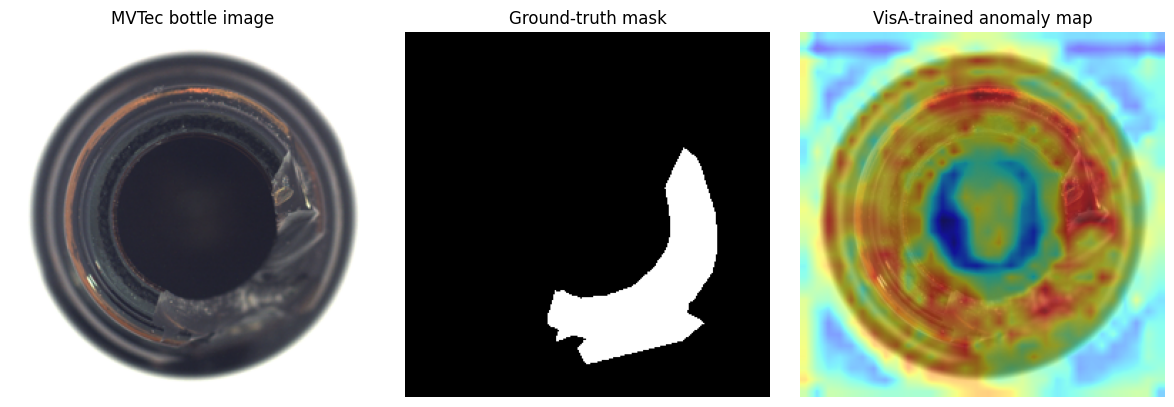


Saved result to: /kaggle/working/results/cross_visa_candle_to_mvtec_bottle.csv


In [23]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

MVTEC = "/kaggle/input/datasets/rimjhimbhura/dataset/datasets/mvtec_anomaly_detection"
target_category = "bottle"

# Collect all official MVTec bottle test images and labels
test_root = os.path.join(MVTEC, target_category, "test")
target_paths = []
target_labels = []
target_masks = []

for defect_type in sorted(os.listdir(test_root)):
    defect_dir = os.path.join(test_root, defect_type)
    if not os.path.isdir(defect_dir):
        continue

    is_anomaly = defect_type != "good"

    for filename in sorted(os.listdir(defect_dir)):
        if not filename.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
            continue

        image_path = os.path.join(defect_dir, filename)
        target_paths.append(image_path)
        target_labels.append(int(is_anomaly))

        if is_anomaly:
            mask_path = os.path.join(
                MVTEC, target_category, "ground_truth",
                defect_type, os.path.splitext(filename)[0] + "_mask.png"
            )
            target_masks.append(mask_path)
        else:
            target_masks.append(None)

print("Target dataset: MVTec AD")
print("Target category:", target_category)
print("Test images:", len(target_paths))
print("Normal images:", target_labels.count(0))
print("Anomalous images:", target_labels.count(1))

# Score target images using the VisA candle bank
memory_bank = visa_candle_memory_bank
anomaly_maps_reverse = []
image_scores_reverse = []

target_dataset = ImagePathDataset(target_paths, transform)
target_loader = DataLoader(
    target_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2
)

feature_extractor.eval()

with torch.inference_mode():
    for images in tqdm(target_loader, desc="Reverse cross-dataset evaluation"):
        images = images.to(DEVICE)
        batch_features = feature_extractor(images)

        for features in batch_features:
            patches = features.permute(1, 2, 0).reshape(-1, 128)
            patches = F.normalize(patches, p=2, dim=1)

            distance_parts = []
            for chunk in patches.split(128):
                distances = torch.cdist(
                    chunk.unsqueeze(0),
                    memory_bank.unsqueeze(0)
                ).squeeze(0)
                distance_parts.append(distances.min(dim=1).values)

            heatmap = torch.cat(distance_parts).reshape(1, 1, 32, 32)
            heatmap = F.interpolate(
                heatmap,
                size=(256, 256),
                mode="bilinear",
                align_corners=False
            )[0, 0].cpu().numpy()

            anomaly_maps_reverse.append(heatmap)

            flat = heatmap.ravel()
            k = max(1, int(0.01 * len(flat)))
            image_scores_reverse.append(
                float(np.mean(np.partition(flat, -k)[-k:]))
            )

# Image-level AUROC
image_auc_reverse = roc_auc_score(
    target_labels, image_scores_reverse
)
print(f"\nVisA candle -> MVTec bottle image AUROC: {image_auc_reverse:.4f}")

# Pixel-level AUROC at 64x64
pixel_scores_reverse = []
pixel_labels_reverse = []
missing_masks_reverse = 0

for label, mask_path, heatmap in zip(
    target_labels, target_masks, anomaly_maps_reverse
):
    score_small = np.asarray(
        Image.fromarray(heatmap.astype(np.float32)).resize(
            (64, 64), Image.Resampling.BILINEAR
        )
    )

    if label == 0:
        mask_small = np.zeros((64, 64), dtype=np.uint8)
    elif mask_path and os.path.exists(mask_path):
        mask_img = Image.open(mask_path).convert("L").resize(
            (64, 64), Image.Resampling.NEAREST
        )
        mask_small = (
            np.asarray(mask_img) > 0
        ).astype(np.uint8)
    else:
        missing_masks_reverse += 1
        continue

    pixel_scores_reverse.extend(score_small.ravel())
    pixel_labels_reverse.extend(mask_small.ravel())

if (
    missing_masks_reverse == 0
    and len(np.unique(pixel_labels_reverse)) == 2
):
    pixel_auc_reverse = roc_auc_score(
        pixel_labels_reverse, pixel_scores_reverse
    )
    print(
        "VisA candle -> MVTec bottle pixel AUROC (64x64): "
        f"{pixel_auc_reverse:.4f}"
    )
else:
    pixel_auc_reverse = np.nan
    print("Pixel AUROC unavailable; check masks.")

print("Missing masks:", missing_masks_reverse)

# Visualize the first anomalous target image
anomaly_indices = [
    i for i, label in enumerate(target_labels) if label == 1
]

if anomaly_indices:
    idx = anomaly_indices[0]
    original = Image.open(target_paths[idx]).convert("RGB").resize((256, 256))

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(original)
    axes[0].set_title("MVTec bottle image")

    if target_masks[idx] and os.path.exists(target_masks[idx]):
        gt = Image.open(target_masks[idx]).convert("L").resize(
            (256, 256), Image.Resampling.NEAREST
        )
        axes[1].imshow(gt, cmap="gray")
    axes[1].set_title("Ground-truth mask")

    axes[2].imshow(original)
    axes[2].imshow(anomaly_maps_reverse[idx], cmap="jet", alpha=0.5)
    axes[2].set_title("VisA-trained anomaly map")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Save reverse-transfer result
result_dir = "/kaggle/working/results"
os.makedirs(result_dir, exist_ok=True)

reverse_result = pd.DataFrame([{
    "source_dataset": "VisA",
    "source_category": "candle",
    "target_dataset": "MVTec AD",
    "target_category": "bottle",
    "train_images_source": len(source_train_paths),
    "test_images_target": len(target_paths),
    "image_AUROC": image_auc_reverse,
    "pixel_AUROC_64": pixel_auc_reverse,
    "missing_masks": missing_masks_reverse
}])

save_path = os.path.join(
    result_dir, "cross_visa_candle_to_mvtec_bottle.csv"
)
reverse_result.to_csv(save_path, index=False)

print("\nSaved result to:", save_path)


In [24]:

import os
import pandas as pd

RESULT_DIR = "/kaggle/working/results"

# Load within-dataset results
mvtec_path = os.path.join(
    RESULT_DIR, "mvtec_unsupervised_results.csv"
)
visa_path = os.path.join(
    RESULT_DIR, "visa_unsupervised_results.csv"
)

if not os.path.exists(mvtec_path):
    raise FileNotFoundError(f"Missing file: {mvtec_path}")

if not os.path.exists(visa_path):
    raise FileNotFoundError(f"Missing file: {visa_path}")

mvtec_df = pd.read_csv(mvtec_path)
visa_df = pd.read_csv(visa_path)

# Standardize column names for a common table
mvtec_df["experiment"] = "Within-dataset unsupervised"
mvtec_df["source_dataset"] = "MVTec AD"
mvtec_df["target_dataset"] = "MVTec AD"

visa_df["experiment"] = "Within-dataset unsupervised"
visa_df["source_dataset"] = "VisA"
visa_df["target_dataset"] = "VisA"

# Load cross-dataset results when available
cross_files = [
    "cross_mvtec_bottle_to_visa_candle.csv",
    "cross_visa_candle_to_mvtec_bottle.csv"
]

cross_frames = []

for filename in cross_files:
    path = os.path.join(RESULT_DIR, filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        df["experiment"] = "Cross-dataset unsupervised"
        cross_frames.append(df)
        print("Loaded:", filename)
    else:
        print("Not found yet:", filename)

# Combine all results
all_frames = [mvtec_df, visa_df] + cross_frames
master_df = pd.concat(all_frames, ignore_index=True, sort=False)

# Arrange the most useful columns first
preferred_columns = [
    "experiment",
    "source_dataset",
    "source_category",
    "target_dataset",
    "target_category",
    "dataset",
    "category",
    "train_images",
    "test_images",
    "train_images_source",
    "test_images_target",
    "image_AUROC",
    "pixel_AUROC_64",
    "missing_masks"
]

columns = [c for c in preferred_columns if c in master_df.columns]
master_df = master_df[columns]

master_path = os.path.join(
    RESULT_DIR, "master_unsupervised_results.csv"
)
master_df.to_csv(master_path, index=False)

print("\nTotal experiment rows:", len(master_df))
print("Saved master table to:", master_path)

display(master_df)


Loaded: cross_mvtec_bottle_to_visa_candle.csv
Loaded: cross_visa_candle_to_mvtec_bottle.csv

Total experiment rows: 29
Saved master table to: /kaggle/working/results/master_unsupervised_results.csv


,experiment,source_dataset,source_category,target_dataset,target_category,dataset,category,train_images,test_images,train_images_source,test_images_target,image_AUROC,pixel_AUROC_64,missing_masks
0,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,bottle,209.0,83.0,NaN,NaN,0.999206,0.980387,0
1,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,cable,224.0,150.0,NaN,NaN,0.958208,0.891386,0
2,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,capsule,219.0,132.0,NaN,NaN,0.870762,0.963859,0
3,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,carpet,280.0,117.0,NaN,NaN,0.999599,0.980888,0
4,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,grid,264.0,78.0,NaN,NaN,0.944862,0.979259,0
5,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,hazelnut,391.0,110.0,NaN,NaN,0.987500,0.973396,0
6,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,leather,245.0,124.0,NaN,NaN,1.000000,0.995970,0
7,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,metal_nut,220.0,115.0,NaN,NaN,0.967742,0.906379,0
8,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,pill,267.0,167.0,NaN,NaN,0.953082,0.926356,0
9,Within-dataset unsupervised,MVTec AD,NaN,MVTec AD,NaN,NaN,screw,320.0,160.0,NaN,NaN,0.689076,0.973002,0


In [25]:

# Category-level means for the within-dataset experiments
within_df = master_df[
    master_df["experiment"] == "Within-dataset unsupervised"
].copy()

for dataset_name in ["MVTec AD", "VisA"]:
    subset = within_df[within_df["target_dataset"] == dataset_name]

    print(f"\n{dataset_name} — {len(subset)} categories")
    print(
        "Mean image AUROC:",
        round(subset["image_AUROC"].mean(), 4)
    )
    print(
        "Mean pixel AUROC:",
        round(subset["pixel_AUROC_64"].mean(), 4)
    )

print("\nCross-dataset pilot results:")
display(
    master_df[
        master_df["experiment"] == "Cross-dataset unsupervised"
    ][[
        "source_dataset",
        "source_category",
        "target_dataset",
        "target_category",
        "image_AUROC",
        "pixel_AUROC_64"
    ]]
)



MVTec AD — 15 categories
Mean image AUROC: 0.9479
Mean pixel AUROC: 0.9395

VisA — 12 categories
Mean image AUROC: 0.8824
Mean pixel AUROC: 0.9262

Cross-dataset pilot results:


,source_dataset,source_category,target_dataset,target_category,image_AUROC,pixel_AUROC_64
27,MVTec AD,bottle,VisA,candle,0.632900,0.883892
28,VisA,candle,MVTec AD,bottle,0.910317,0.731907
